# Combine: Part A + Part B (PP2)

Goal: predict the price per perch of a land in a future year (for example 2028), with a low / mid / high range.

How it works:
- Part A (land value model) gives the **base price** at the 2025-H1 level, from area, land size and land type.
- Part B (LVI trend) gives how much the market grows: `LVI_future / 256.4`.
- Future price = base price x (LVI_future / 256.4)

Steps:
1. Load the Part A models and the Part B forecast
2. Build an area table (154 areas, location features are fixed per area)
3. Write `predict_base()` for Part A and `lvi_growth()` for Part B
4. Combine them in `predict_price(area, perches, land_type, year, half)`
5. Test it with examples, a plot and a sanity check

Note: training data is augmented and calibrated to the CBSL LVI.


In [1]:
# Import the libraries we need
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Folders (this notebook is in notebooks/combine, so two levels up)
MODEL_DIR = "../../models/"
DATA_DIR = "../../data/processed/"
REPORT_DIR = "../../reports/"

print("Libraries ready")


Libraries ready


In [2]:
# Load the three fitted Part A models (saved in Notebook 03)
models = {
    "Ridge": joblib.load(MODEL_DIR + "ridge_model.joblib"),
    "Random Forest": joblib.load(MODEL_DIR + "random_forest_model.joblib"),
    "XGBoost": joblib.load(MODEL_DIR + "xgboost_model.joblib"),
}

# Load the split details (it also holds the list of 32 features and the target name)
with open(MODEL_DIR + "split_info.json") as f:
    split_info = json.load(f)

FEATURES = split_info["features"]
TARGET = split_info["target"]

print("Models loaded:", list(models))
print("Number of features:", len(FEATURES))
print("Target:", TARGET)


Models loaded: ['Ridge', 'Random Forest', 'XGBoost']
Number of features: 32
Target: log_price_adj


In [3]:
# Load the Part B LVI forecast (low / mid / high for each future half-year)
lvi_forecast = pd.read_csv(REPORT_DIR + "model_b/model_b_lvi_forecast.csv")

# Load the small facts saved by Part B
with open(REPORT_DIR + "model_b/model_b_info.json") as f:
    b_info = json.load(f)

# The base level of Part A prices is the last known LVI (2025-H1)
LVI_BASE = b_info["last_lvi"]

print("Chosen Part B model:", b_info["chosen_model"])
print("Base LVI (2025-H1):", LVI_BASE)
display(lvi_forecast)


Chosen Part B model: Drift
Base LVI (2025-H1): 256.4


,period,horizon,low,mid,high
0,2025-H2,1,261.5,266.2,270.9
1,2026-H1,2,266.2,276.0,285.7
2,2026-H2,3,270.7,285.7,300.8
3,2027-H1,4,274.7,295.5,316.3
4,2027-H2,5,278.4,305.3,332.1
5,2028-H1,6,281.8,315.0,348.3
6,2028-H2,7,284.9,324.8,364.8


In [4]:
# Load the full Part A data (used only to build the area table)
df_all = pd.read_csv(DATA_DIR + "land_model_data.csv")

# The 5 features that describe the land itself (the user gives these)
LAND_FEATURES = ["Land_size(Perches)", "type_residential", "type_commercial",
                 "type_agricultural", "type_other"]

# The other 27 features describe the area, and they are fixed for each area
AREA_FEATURES = [f for f in FEATURES if f not in LAND_FEATURES]

# One row per area: take the first row of each area (all rows of an area are the same)
area_table = df_all.groupby("Address")[AREA_FEATURES].first()

# Lower case area names make searching easier (for example "Narahenpita" -> "narahenpita")
area_table.index = area_table.index.str.lower()

print("Number of areas:", len(area_table))
print("Number of area features:", len(AREA_FEATURES))
print("First 10 areas:", list(area_table.index[:10]))
display(area_table.head(3))


Number of areas: 154
Number of area features: 27
First 10 areas: ['narahenpita', 'angulana', 'arangala', 'athurugiriya', 'attidiya', 'avissawella', 'bambalapitiya', 'bangalawatta', 'batakettara', 'battaramulla']


,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km
Address,,,,,,,,,,,,,,,,,,,,,,,,,,,
narahenpita,7.47,2,0.533693,11,0.928453,1,1.240942,3,0.724112,4,1.087296,5.384152,0.890411,0.586072,30,0.683181,7,0.546364,2,0.702011,6,0.824186,3,0.440549,15,0.831389,3
angulana,16.59,0,3.194163,5,1.268013,0,2.022654,0,6.604363,0,2.608909,11.974716,0.081116,1.376162,9,1.533027,3,6.494698,0,5.410539,0,2.561487,0,0.686166,3,1.817842,1
arangala,16.09,0,5.341339,3,0.489890,0,5.050682,0,3.670276,0,3.208476,1.913461,4.504202,0.650962,6,1.625135,1,4.726630,0,3.051715,0,4.329561,0,0.789134,7,0.681933,1


In [5]:
# The 4 land types the model knows
LAND_TYPES = ["residential", "commercial", "agricultural", "other"]

def predict_base(area, perches, land_type, model_name="Random Forest"):
    """Part A: base price per perch (Rs) at the 2025-H1 level."""
    area = area.strip().lower()
    if area not in area_table.index:
        raise ValueError(f"Unknown area: {area}")

    # land_type can be one word ("residential") or a list (["residential", "commercial"])
    types = [land_type] if isinstance(land_type, str) else list(land_type)
    for t in types:
        if t not in LAND_TYPES:
            raise ValueError(f"Unknown land type: {t}. Use one of {LAND_TYPES}")

    # Start with the 27 fixed features of this area
    row = area_table.loc[area].copy()

    # Add the land features given by the user
    row["Land_size(Perches)"] = perches
    for t in LAND_TYPES:
        row["type_" + t] = 1 if t in types else 0

    # Put the features in the same order as in training, then predict
    X_one = pd.DataFrame([row])[FEATURES]
    log_price = models[model_name].predict(X_one)[0]

    # The model gives log price, so exp gives Rupees
    return float(np.exp(log_price))

# Quick test: the same land, with all three models
for name in models:
    price = predict_base("narahenpita", 10, "residential", model_name=name)
    print(f"{name}: Rs {price:,.0f} per perch (2025-H1 level)")


Ridge: Rs 9,231,753 per perch (2025-H1 level)
Random Forest: Rs 10,906,385 per perch (2025-H1 level)
XGBoost: Rs 11,342,120 per perch (2025-H1 level)


In [6]:
def lvi_growth(year, half):
    """Part B: LVI low / mid / high for a future half-year, and the growth multiplier."""
    period = f"{year}-H{half}"

    # 2025-H1 is the base: no growth yet
    if period == "2025-H1":
        low = mid = high = LVI_BASE
    else:
        row = lvi_forecast[lvi_forecast["period"] == period]
        if row.empty:
            raise ValueError(f"No forecast for {period}. Use 2025-H1 to 2028-H2 (half = 1 or 2).")
        low, mid, high = row[["low", "mid", "high"]].iloc[0]

    # Growth multiplier = LVI_future / LVI_base (Part A prices are at the 2025-H1 level)
    return {
        "period": period,
        "lvi_low": float(low), "lvi_mid": float(mid), "lvi_high": float(high),
        "growth_low": float(low) / LVI_BASE,
        "growth_mid": float(mid) / LVI_BASE,
        "growth_high": float(high) / LVI_BASE,
    }

# Quick test: three periods
for y, h in [(2025, 1), (2026, 2), (2028, 2)]:
    g = lvi_growth(y, h)
    print(g["period"], "| growth low / mid / high =",
          round(g["growth_low"], 3), "/", round(g["growth_mid"], 3), "/", round(g["growth_high"], 3))


2025-H1 | growth low / mid / high = 1.0 / 1.0 / 1.0
2026-H2 | growth low / mid / high = 1.056 / 1.114 / 1.173
2028-H2 | growth low / mid / high = 1.111 / 1.267 / 1.423


In [7]:
def predict_price(area, perches, land_type, year, half, model_name="Random Forest"):
    """Future price per perch (Rs) with a low / mid / high range, and the total price."""
    # Part A: base price at the 2025-H1 level
    base = predict_base(area, perches, land_type, model_name)

    # Part B: how much the market grows until the target half-year
    g = lvi_growth(year, half)

    # Future price = base price x growth multiplier
    low = base * g["growth_low"]
    mid = base * g["growth_mid"]
    high = base * g["growth_high"]

    return {
        "area": area, "perches": perches, "land_type": land_type,
        "period": g["period"], "model": model_name,
        "base_price_2025H1": round(base),
        "price_per_perch_low": round(low),
        "price_per_perch_mid": round(mid),
        "price_per_perch_high": round(high),
        "total_low": round(low * perches),
        "total_mid": round(mid * perches),
        "total_high": round(high * perches),
    }

# Quick test: 10 perch residential land in Narahenpita, in 2028-H2
result = predict_price("narahenpita", 10, "residential", 2028, 2)
for key, value in result.items():
    print(key, ":", value)


area : narahenpita
perches : 10
land_type : residential
period : 2028-H2
model : Random Forest
base_price_2025H1 : 10906385
price_per_perch_low : 12118678
price_per_perch_mid : 13815888
price_per_perch_high : 15517352
total_low : 121186780
total_mid : 138158884
total_high : 155173525


In [9]:
# Example lands: (area, perches, land type)
examples = [
    ("narahenpita", 10, "residential"),
    ("bambalapitiya", 20, "commercial"),
    ("angulana", 8, "residential"),
    ("avissawella", 50, "agricultural"),
]

# Target periods: every half-year from 2026-H1 to 2028-H2
targets = [(year, half) for year in [2026, 2027, 2028] for half in [1, 2]]

rows = []
for area, perches, land_type in examples:
    for year, half in targets:
        r = predict_price(area, perches, land_type, year, half)
        rows.append({
            "area": area, "perches": perches, "type": land_type,
            "period": r["period"],
            "per_perch_low": r["price_per_perch_low"],
            "per_perch_mid": r["price_per_perch_mid"],
            "per_perch_high": r["price_per_perch_high"],
        })

example_table = pd.DataFrame(rows)

# Show Rs values with commas
display(example_table.style.format({
    "per_perch_low": "{:,.0f}", "per_perch_mid": "{:,.0f}", "per_perch_high": "{:,.0f}"}))


,area,perches,type,period,per_perch_low,per_perch_mid,per_perch_high
0,narahenpita,10,residential,2026-H1,"11,323,243","11,740,102","12,152,707"
1,narahenpita,10,residential,2026-H2,"11,514,658","12,152,707","12,795,010"
2,narahenpita,10,residential,2027-H1,"11,684,805","12,569,566","13,454,327"
3,narahenpita,10,residential,2027-H2,"11,842,190","12,986,425","14,126,406"
4,narahenpita,10,residential,2028-H1,"11,986,814","13,399,030","14,815,499"
5,narahenpita,10,residential,2028-H2,"12,118,678","13,815,888","15,517,352"
6,bambalapitiya,20,commercial,2026-H1,"17,324,747","17,962,548","18,593,840"
7,bambalapitiya,20,commercial,2026-H2,"17,617,615","18,593,840","19,576,574"
8,bambalapitiya,20,commercial,2027-H1,"17,877,942","19,231,641","20,585,340"
9,bambalapitiya,20,commercial,2027-H2,"18,118,744","19,869,442","21,613,631"


In [10]:
# Check 1: at 2025-H1 the mid price must be the same as the base price (no growth yet)
r = predict_price("narahenpita", 10, "residential", 2025, 1)
print("Check 1 (2025-H1 mid = base):", r["price_per_perch_mid"] == r["base_price_2025H1"])

# Check 2: low <= mid <= high in every row
ok2 = ((example_table["per_perch_low"] <= example_table["per_perch_mid"]) &
       (example_table["per_perch_mid"] <= example_table["per_perch_high"])).all()
print("Check 2 (low <= mid <= high):", ok2)

# Check 3: the mid price goes up with time, and the range gets wider, for every land
ok3, ok4 = True, True
for area, group in example_table.groupby("area"):
    group = group.sort_values("period")
    width = group["per_perch_high"] - group["per_perch_low"]
    ok3 = ok3 and group["per_perch_mid"].is_monotonic_increasing
    ok4 = ok4 and width.is_monotonic_increasing
print("Check 3 (mid price rises with time):", ok3)
print("Check 4 (range gets wider with time):", ok4)

# Check 4: an unknown area and a period that is too far must give clear errors
for bad in [lambda: predict_price("nowhere", 10, "residential", 2028, 2),
            lambda: predict_price("narahenpita", 10, "residential", 2030, 1)]:
    try:
        bad()
    except ValueError as e:
        print("Error caught:", e)


Check 1 (2025-H1 mid = base): True
Check 2 (low <= mid <= high): True
Check 3 (mid price rises with time): True
Check 4 (range gets wider with time): True
Error caught: Unknown area: nowhere
Error caught: No forecast for 2030-H1. Use 2025-H1 to 2028-H2 (half = 1 or 2).


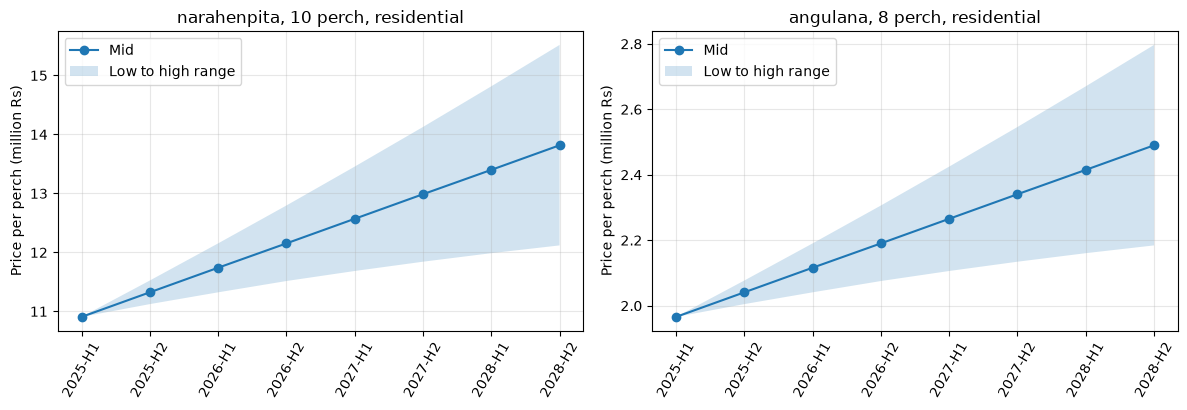

In [11]:
# Plot the price over time for two example lands (mid line and low-high band)
periods = ["2025-H1", "2025-H2", "2026-H1", "2026-H2", "2027-H1", "2027-H2", "2028-H1", "2028-H2"]
lands = [("narahenpita", 10, "residential"), ("angulana", 8, "residential")]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, (area, perches, land_type) in zip(axes, lands):
    low, mid, high = [], [], []
    for p in periods:
        year, half = int(p[:4]), int(p[-1])
        r = predict_price(area, perches, land_type, year, half)
        low.append(r["price_per_perch_low"] / 1e6)    # in million Rs
        mid.append(r["price_per_perch_mid"] / 1e6)
        high.append(r["price_per_perch_high"] / 1e6)

    ax.plot(periods, mid, marker="o", label="Mid")
    ax.fill_between(periods, low, high, alpha=0.2, label="Low to high range")
    ax.set_title(f"{area}, {perches} perch, {land_type}")
    ax.set_ylabel("Price per perch (million Rs)")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [12]:
import os

OUT = REPORT_DIR + "combine/"
os.makedirs(OUT, exist_ok=True)

# Save the example predictions table
example_table.to_csv(OUT + "combine_example_predictions.csv", index=False)

# Save the small facts about how the combine step works
combine_info = {
    "formula": "future price = Part A base price x (LVI_future / LVI_base)",
    "part_a_model_default": "Random Forest",
    "part_a_price_level": "2025-H1",
    "part_b_model": b_info["chosen_model"],
    "lvi_base": LVI_BASE,
    "forecast_periods": "2025-H1 to 2028-H2",
    "range_note": "Low/high shows only the Part B (LVI trend) uncertainty. The Part A error (test MAPE about 23%) is not included.",
    "data_note": "Part A training data is augmented and calibrated to the CBSL LVI.",
}
with open(OUT + "combine_info.json", "w") as f:
    json.dump(combine_info, f, indent=2)

print("Saved to", OUT)
print(sorted(os.listdir(OUT)))


Saved to ../../reports/combine/
['combine_example_predictions.csv', 'combine_info.json']


## Summary and limitations

**Result.** `predict_price(area, perches, land_type, year, half)` gives the price per perch with a low / mid / high range, for any half-year from 2025-H1 to 2028-H2.
Future price = Part A base price (2025-H1 level) x (LVI_future / 256.4).
Example: 10 perch residential land in Narahenpita in 2028-H2: base Rs 10.9 million, mid Rs 13.8 million per perch (range 12.1 to 15.5 million).

**Limitations**
- The training data is augmented and calibrated to the CBSL LVI. The results are not an independent validation on real transactions.
- The low / high range shows only the Part B (LVI trend) uncertainty. The Part A error (test MAPE about 23%) is not included, so the real uncertainty is wider.
- The low case never goes below today's price, because even the low LVI forecast is above 256.4. A falling market is not covered.
- The same LVI growth is used for every area. Part B assumes the average growth continues.
- Part A models were trained on the 80% train data only (not refitted on all data).
- Only 154 known Colombo areas, and asking prices, not transaction prices.

**Next.** Simple frontend (area dropdown, land size, land type, target period) and validation with real 2025/26 listings.
